# FB15k-237 — eksploracyjna analiza danych


In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from IPython.display import display

SEED = 42
TOP_K = 15
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_columns', 15)


In [2]:
DATASET = 'FB15k-237'
FILE_NAME = 'fb15k-237_train.tsv'
candidates = [Path.cwd() / 'data', Path.cwd()]
DATA_DIR = next((p for p in candidates if (p / FILE_NAME).is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError(f'Nie znaleziono {FILE_NAME}. Uruchom z katalogu repozytorium lub data/.')
path = DATA_DIR / FILE_NAME

def read_triples(path):
    options = dict(dtype='string', keep_default_na=False, on_bad_lines='error')
    if path.suffix == '.tsv':
        return pd.read_csv(path, sep='\t', header=None,
                           names=['head', 'relation', 'tail'], **options)
    return pd.read_csv(path, **options)

raw = read_triples(path)
assert list(raw.columns) == ['head', 'relation', 'tail'], raw.columns.tolist()
digest = hashlib.sha256(path.read_bytes()).hexdigest()
display(pd.Series({'plik': path.name, 'rozmiar_MiB': path.stat().st_size / 2**20,
                   'SHA256': digest, 'wiersze': len(raw)}, name='źródło').to_frame())
display(raw.head(8))
display(raw.dtypes.to_frame('dtype'))


,źródło
plik,fb15k-237_train.tsv
rozmiar_MiB,20.032098
SHA256,61099230e4439f90885ca9767739e31e8e32f54736fa1c35952b27997bc7c08a
wiersze,272115


,head,relation,tail
0,/m/027rn,/location/country/form_of_government,/m/06cx9
1,/m/017dcd,/tv/tv_program/regular_cast./tv/regular_tv_appearance/actor,/m/06v8s0
2,/m/07s9rl0,/media_common/netflix_genre/titles,/m/0170z3
3,/m/01sl1q,/award/award_winner/awards_won./award/award_honor/award_winner,/m/044mz_
4,/m/0cnk2q,/soccer/football_team/current_roster./sports/sports_team_roster/position,/m/02nzb8
5,/m/04nrcg,/soccer/football_team/current_roster./soccer/football_roster_position/position,/m/02sdk9v
6,/m/07nznf,/film/actor/film./film/performance/film,/m/014lc_
7,/m/02qyp19,/award/award_category/nominees./award/award_nomination/nominated_for,/m/02d413


,dtype
head,string
relation,string
tail,string


## 1. Kontrola jakości danych


In [3]:
missing = raw.isna()
blank = raw.apply(lambda col: col.str.strip().eq('').fillna(False))
padded = raw.apply(lambda col: col.ne(col.str.strip()).fillna(False))
display(pd.DataFrame({'braki': missing.sum(), 'puste_lub_białe_znaki': blank.sum(),
                      'brzegowe_białe_znaki': padded.sum()}))
valid_mask = ~(missing | blank).any(axis=1)
valid = raw.loc[valid_mask].copy()
duplicate_count = int(valid.duplicated().sum())
df = valid.drop_duplicates().reset_index(drop=True)
assert not df.empty, 'Brak poprawnych trójek do analizy.'
quality = pd.Series({'wiersze_surowe': len(raw), 'wiersze_niepoprawne': int((~valid_mask).sum()),
                     'nadmiarowe_duplikaty': duplicate_count, 'unikalne_poprawne_trójki': len(df),
                     'pętle_własne': int(df['head'].eq(df['tail']).sum())}, name='liczba')
display(quality.to_frame())
display(df.loc[df['head'].eq(df['tail'])].head(5))


,braki,puste_lub_białe_znaki,brzegowe_białe_znaki
head,0,0,0
relation,0,0,0
tail,0,0,0


,liczba
wiersze_surowe,272115
wiersze_niepoprawne,0
nadmiarowe_duplikaty,0
unikalne_poprawne_trójki,272115
pętle_własne,1625


,head,relation,tail
113,/m/0t015,/location/hud_county_place/place,/m/0t015
193,/m/052nd,/education/educational_institution_campus/educational_institution,/m/052nd
245,/m/01fpvz,/education/educational_institution_campus/educational_institution,/m/01fpvz
546,/m/0wh3,/location/hud_county_place/place,/m/0wh3
765,/m/017zq0,/education/educational_institution/campuses,/m/017zq0


## 2. Statystyki grafu


In [4]:
entities = pd.Index(pd.unique(pd.concat([df['head'], df['tail']], ignore_index=True)), name='entity')
relations = pd.Index(sorted(df['relation'].unique()), name='relation')
n, m, r = len(entities), len(df), len(relations)
heads, tails = set(df['head']), set(df['tail'])
out_degree = df.groupby('head').size().reindex(entities, fill_value=0)
in_degree = df.groupby('tail').size().reindex(entities, fill_value=0)
entity_stats = pd.DataFrame({'in_degree': in_degree, 'out_degree': out_degree})
entity_stats['degree'] = in_degree + out_degree
entity_stats['out_relations'] = df.groupby('head')['relation'].nunique().reindex(entities, fill_value=0)
entity_stats['in_relations'] = df.groupby('tail')['relation'].nunique().reindex(entities, fill_value=0)
entity_stats['role_relations'] = entity_stats['out_relations'] + entity_stats['in_relations']
directed_pairs = df[['head', 'tail']].drop_duplicates()
nonloop_pairs = directed_pairs.loc[directed_pairs['head'].ne(directed_pairs['tail'])]
summary = pd.Series({'trójki': m, 'encje': n, 'relacje': r,
                     'unikalne_skierowane_pary': len(directed_pairs),
                     'gęstość_bez_pętli': len(nonloop_pairs) / (n * (n - 1)) if n > 1 else np.nan,
                     'tylko_head': len(heads - tails), 'tylko_tail': len(tails - heads),
                     'obie_role': len(heads & tails), 'trójki_na_encję': m / n}, name=DATASET)
display(summary.to_frame())
display(entity_stats.describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(2))
assert entity_stats['in_degree'].sum() == entity_stats['out_degree'].sum() == m
assert entity_stats['degree'].sum() == 2 * m


,FB15k-237
trójki,272115.000000
encje,14505.000000
relacje,237.000000
unikalne_skierowane_pary,246236.000000
gęstość_bez_pętli,0.001165
tylko_head,1126.000000
tylko_tail,724.000000
obie_role,12655.000000
trójki_na_encję,18.760083


,in_degree,out_degree,degree,out_relations,in_relations,role_relations
count,14505.00,14505.00,14505.00,14505.00,14505.00,14505.00
mean,18.76,18.76,37.52,6.44,3.88,10.32
std,94.80,29.65,111.19,4.49,2.98,6.96
min,0.00,0.00,1.00,0.00,0.00,1.00
10%,1.00,2.00,5.00,1.00,1.00,2.00
25%,3.00,5.00,11.00,2.00,2.00,4.00
50%,8.00,13.00,22.00,6.00,3.00,10.00
75%,18.00,23.00,41.00,10.00,6.00,15.00
90%,32.00,39.00,68.00,12.00,8.00,19.00
99%,170.96,105.00,272.96,18.00,13.00,29.00


## 3. Rozkład częstości relacji


,wartość
udział_top_1,0.058758
udział_top_5,0.225927
udział_top_10,0.363049
entropia_bity,6.552660
entropia_znormalizowana,0.830634
efektywna_liczba_relacji,93.874391


,trójki,udział,udział_skumulowany
relation,,,
/award/award_nominee/award_nominations./award/award_nomination/award_nominee,15989,0.058758,0.058758
/film/film/release_date_s./film/film_regional_release_date/film_release_region,12893,0.047381,0.106139
/award/award_nominee/award_nominations./award/award_nomination/award,12157,0.044676,0.150815
/people/person/profession,10945,0.040222,0.191037
/film/actor/film./film/performance/film,9494,0.03489,0.225927
/award/award_category/nominees./award/award_nomination/nominated_for,9465,0.034783,0.26071
/award/award_winner/awards_won./award/award_honor/award_winner,8423,0.030954,0.291663
/film/film/genre,7268,0.026709,0.318373
/award/award_nominee/award_nominations./award/award_nomination/nominated_for,6277,0.023067,0.34144


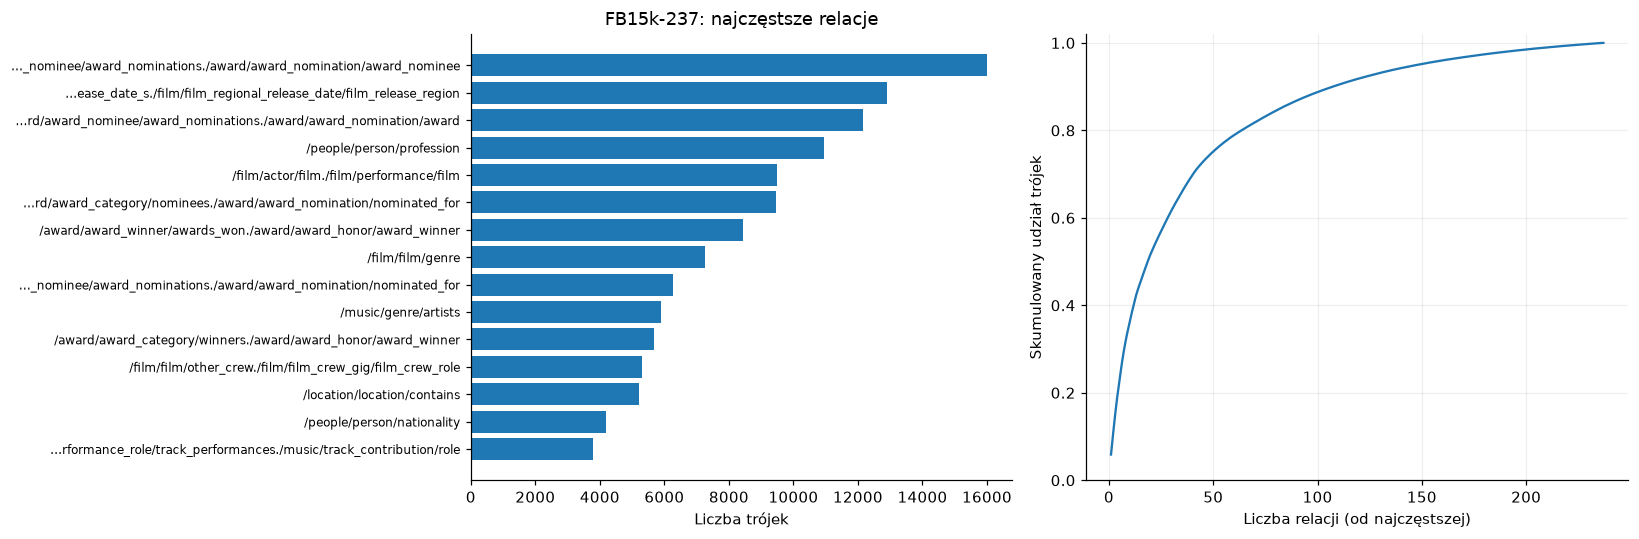

In [5]:
relation_counts = df['relation'].value_counts()
relation_share = relation_counts / m
entropy = float(-(relation_share * np.log2(relation_share)).sum())
relation_balance = pd.Series({'udział_top_1': relation_share.iloc[0],
                              'udział_top_5': relation_share.head(5).sum(),
                              'udział_top_10': relation_share.head(10).sum(),
                              'entropia_bity': entropy,
                              'entropia_znormalizowana': entropy / np.log2(r) if r > 1 else 0.,
                              'efektywna_liczba_relacji': 2**entropy})
display(relation_balance.to_frame('wartość'))
display(pd.DataFrame({'trójki': relation_counts, 'udział': relation_share,
                      'udział_skumulowany': relation_share.cumsum()}).head(20))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
labels = [str(x) if len(str(x)) <= 65 else '…' + str(x)[-64:] for x in relation_counts.head(TOP_K).index]
axes[0].barh(range(len(labels)), relation_counts.head(TOP_K).values)
axes[0].set_yticks(range(len(labels)), labels=labels, fontsize=8)
axes[0].invert_yaxis()
axes[0].set(xlabel='Liczba trójek', title=f'{DATASET}: najczęstsze relacje')
axes[1].plot(np.arange(1, r + 1), relation_share.cumsum().values)
axes[1].set(xlabel='Liczba relacji (od najczęstszej)', ylabel='Skumulowany udział trójek', ylim=(0, 1.02))
axes[1].grid(alpha=.2)
plt.tight_layout()
plt.show()


## 4. Rozkład stopni i różnorodność relacji encji


,wartość
encje_stopień_1,365.000000
udział_stopień_do_5,0.111065
udział_stopnia_top_1proc_encji,0.182800
mediana_liczby_relacji_z_rolą,10.000000


,in_degree,out_degree,degree,out_relations,in_relations,role_relations
entity,,,,,,
/m/09c7w0,6289,1325,7614,21,37,58
/m/09nqf,4285,1,4286,1,14,15
/m/08mbj5d,3612,0,3612,0,1,1
/m/04ztj,2586,406,2992,2,1,3
/m/05zppz,2928,0,2928,0,2,2
/m/02h40lc,2590,85,2675,5,10,15
/m/02hrh1q,2271,1,2272,1,3,4
/m/07ssc,1443,510,1953,22,33,55
/m/02sdk9v,1178,609,1787,3,3,6


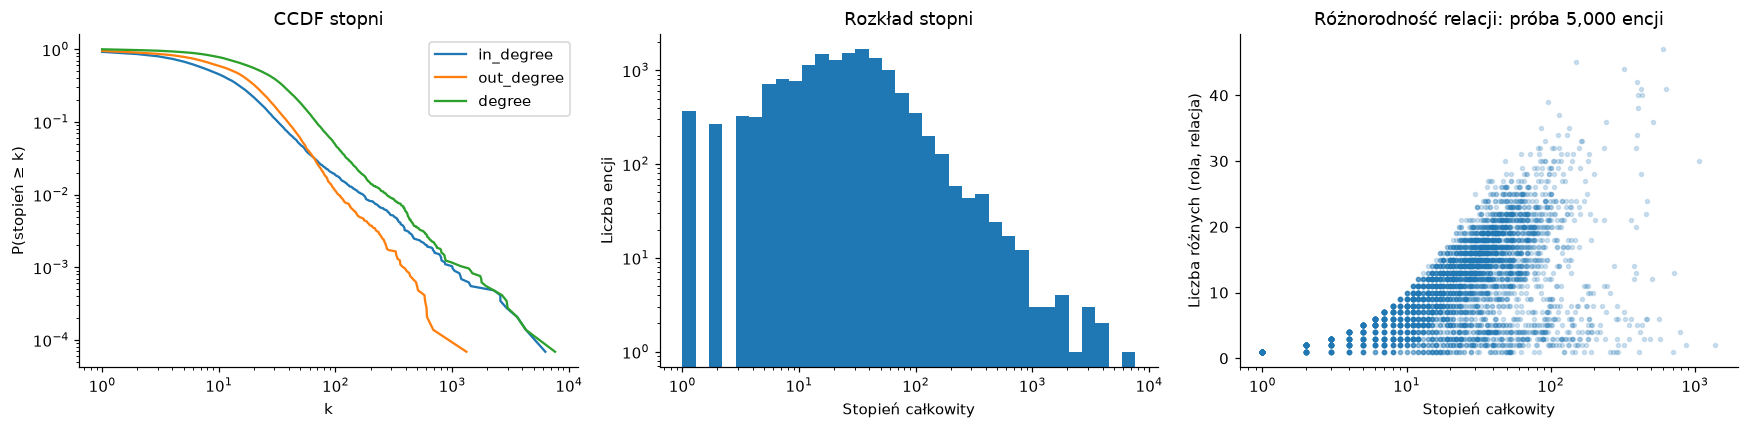

In [6]:
degree = entity_stats['degree']
top_n = max(1, int(np.ceil(.01 * n)))
hub_share = degree.nlargest(top_n).sum() / degree.sum()
display(pd.Series({'encje_stopień_1': int(degree.eq(1).sum()),
                   'udział_stopień_do_5': degree.le(5).mean(),
                   'udział_stopnia_top_1proc_encji': hub_share,
                   'mediana_liczby_relacji_z_rolą': entity_stats['role_relations'].median()}).to_frame('wartość'))
display(entity_stats.sort_values('degree', ascending=False).head(15))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for col in ['in_degree', 'out_degree', 'degree']:
    positive = entity_stats[col].loc[lambda x: x > 0]
    counts = positive.value_counts().sort_index()
    ccdf = counts.iloc[::-1].cumsum().iloc[::-1] / n
    axes[0].plot(counts.index, ccdf, label=col)
axes[0].set(xscale='log', yscale='log', xlabel='k', ylabel='P(stopień ≥ k)', title='CCDF stopni')
axes[0].legend()
bins = np.unique(np.geomspace(1, max(2, degree.max()), 35))
axes[1].hist(degree, bins=bins)
axes[1].set(xscale='log', yscale='log', xlabel='Stopień całkowity', ylabel='Liczba encji', title='Rozkład stopni')
sample = entity_stats.sample(n=min(5000, n), random_state=SEED)
axes[2].scatter(sample['degree'], sample['role_relations'], s=7, alpha=.2)
axes[2].set(xscale='log', xlabel='Stopień całkowity', ylabel='Liczba różnych (rola, relacja)',
            title=f'Różnorodność relacji: próba {len(sample):,} encji')
plt.tight_layout()
plt.show()


## 5. Składowe spójności


In [7]:
h_codes = entities.get_indexer(df['head'])
t_codes = entities.get_indexer(df['tail'])
adjacency = sparse.coo_matrix((np.ones(m, dtype=np.int64), (h_codes, t_codes)), shape=(n, n)).tocsr()
adjacency.data[:] = 1
weak_n, weak_labels = connected_components(adjacency, directed=True, connection='weak')
strong_n, strong_labels = connected_components(adjacency, directed=True, connection='strong')
weak_sizes = pd.Series(np.bincount(weak_labels)).sort_values(ascending=False)
strong_sizes = pd.Series(np.bincount(strong_labels)).sort_values(ascending=False)
display(pd.DataFrame({'liczba_składowych': [weak_n, strong_n],
                      'największa_składowa': [weak_sizes.iloc[0], strong_sizes.iloc[0]],
                      'udział_największej': [weak_sizes.iloc[0] / n, strong_sizes.iloc[0] / n],
                      'składowe_jednoelementowe': [(weak_sizes == 1).sum(), (strong_sizes == 1).sum()]},
                     index=['słabe', 'silne']))
display(weak_sizes.head(10).rename('liczba_encji').to_frame().rename_axis('id_słabej_składowej'))


,liczba_składowych,największa_składowa,udział_największej,składowe_jednoelementowe
słabe,5,14496,0.999380,0
silne,2816,11620,0.801103,2785


,liczba_encji
id_słabej_składowej,
0,14496
3,3
1,2
2,2
4,2


## 6. Kardynalność relacji


,triples,heads,tails,tph,hpt,cardinality,head_tail_jaccard
relation,,,,,,,
/award/award_nominee/award_nominations./award/award_nomination/award_nominee,15989,2334,2341,6.850,6.830,N–N,0.935
/film/film/release_date_s./film/film_regional_release_date/film_release_region,12893,1311,171,9.834,75.398,N–N,0.000
/award/award_nominee/award_nominations./award/award_nomination/award,12157,3336,403,3.644,30.166,N–N,0.000
/people/person/profession,10945,4123,149,2.655,73.456,N–N,0.000
/film/actor/film./film/performance/film,9494,2046,1784,4.640,5.322,N–N,0.000
/award/award_category/nominees./award/award_nomination/nominated_for,9465,239,1587,39.603,5.964,N–N,0.000
/award/award_winner/awards_won./award/award_honor/award_winner,8423,1608,1614,5.238,5.219,N–N,0.926
/film/film/genre,7268,1862,123,3.903,59.089,N–N,0.001
/award/award_nominee/award_nominations./award/award_nomination/nominated_for,6277,2329,1620,2.695,3.875,N–N,0.003


,relations,triples,triple_share
cardinality,,,
1–1,17,4278,0.015721
1–N,26,12536,0.046069
N–1,86,50635,0.186079
N–N,108,204666,0.752131


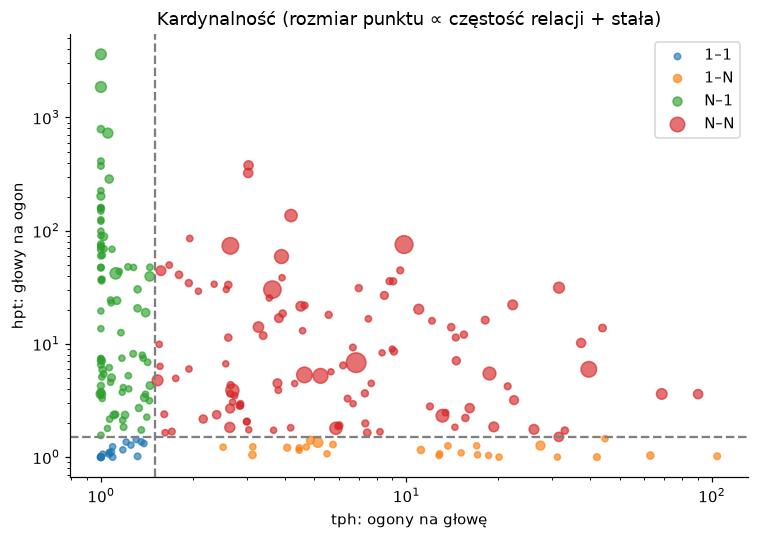

In [8]:
# tph: ogony na głowę; hpt: głowy na ogon. Próg kardynalności: 1.5.
relation_stats = df.groupby('relation').agg(triples=('head', 'size'),
                                           heads=('head', 'nunique'), tails=('tail', 'nunique'))
relation_stats['tph'] = relation_stats['triples'] / relation_stats['heads']
relation_stats['hpt'] = relation_stats['triples'] / relation_stats['tails']
relation_stats['cardinality'] = np.select(
    [(relation_stats['tph'] < 1.5) & (relation_stats['hpt'] < 1.5),
     (relation_stats['tph'] >= 1.5) & (relation_stats['hpt'] < 1.5),
     (relation_stats['tph'] < 1.5) & (relation_stats['hpt'] >= 1.5)],
    ['1–1', '1–N', 'N–1'], default='N–N')
head_sets = {rel: set(group['head']) for rel, group in df.groupby('relation')}
tail_sets = {rel: set(group['tail']) for rel, group in df.groupby('relation')}
relation_stats['head_tail_jaccard'] = [len(head_sets[x] & tail_sets[x]) / len(head_sets[x] | tail_sets[x])
                                       for x in relation_stats.index]
display(relation_stats.sort_values('triples', ascending=False).head(20).round(3))
cardinality_summary = relation_stats.groupby('cardinality').agg(relations=('triples', 'size'), triples=('triples', 'sum'))
cardinality_summary['triple_share'] = cardinality_summary['triples'] / m
display(cardinality_summary)
fig, ax = plt.subplots(figsize=(7, 5))
for category, group in relation_stats.groupby('cardinality'):
    ax.scatter(group['tph'], group['hpt'], s=15 + 150 * group['triples'] / relation_stats['triples'].max(),
               alpha=.65, label=category)
ax.axvline(1.5, linestyle='--', color='grey')
ax.axhline(1.5, linestyle='--', color='grey')
ax.set(xscale='log', yscale='log', xlabel='tph: ogony na głowę', ylabel='hpt: głowy na ogon',
       title='Kardynalność (rozmiar punktu ∝ częstość relacji + stała)')
ax.legend()
plt.tight_layout()
plt.show()


## 7. Podobieństwo zbiorów uczestników relacji


,id,relation
0,R1,/award/award_nominee/award_nominations./award/award_nomination/award_nominee
1,R2,/film/film/release_date_s./film/film_regional_release_date/film_release_region
2,R3,/award/award_nominee/award_nominations./award/award_nomination/award
3,R4,/people/person/profession
4,R5,/film/actor/film./film/performance/film
5,R6,/award/award_category/nominees./award/award_nomination/nominated_for
6,R7,/award/award_winner/awards_won./award/award_honor/award_winner
7,R8,/film/film/genre
8,R9,/award/award_nominee/award_nominations./award/award_nomination/nominated_for
9,R10,/music/genre/artists


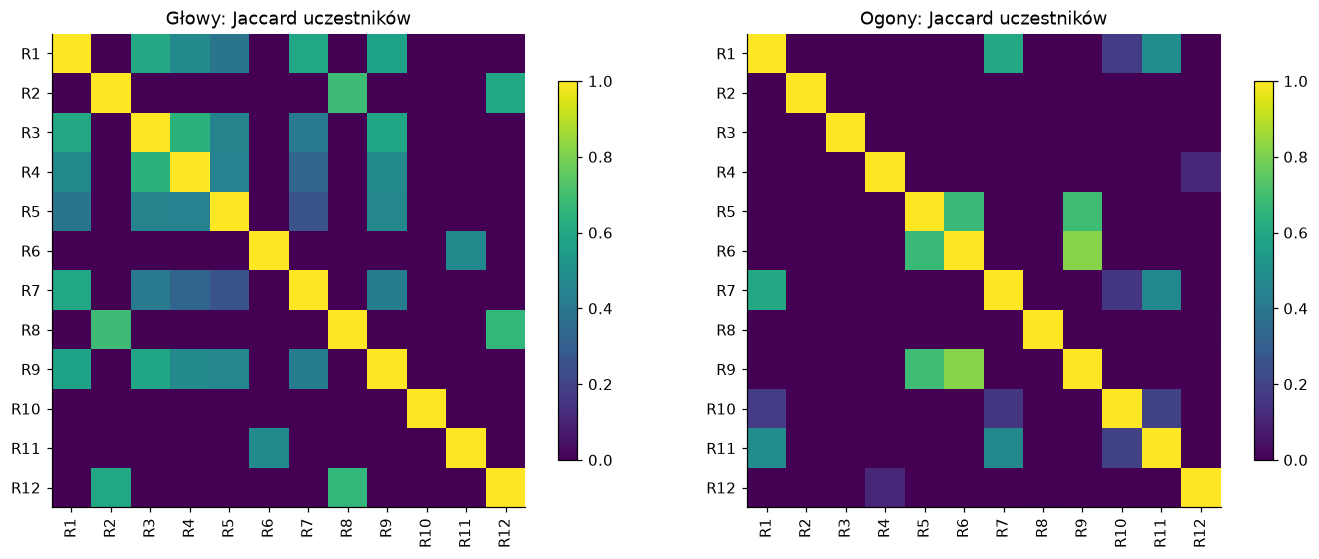

,relation_A,relation_B,head_jaccard,tail_jaccard
16,/film/film/release_date_s./film/film_regional_release_date/film_release_region,/film/film/genre,0.687,0.000
59,/film/film/genre,/film/film/other_crew./film/film_crew_gig/film_crew_role,0.661,0.006
21,/award/award_nominee/award_nominations./award/award_nomination/award,/people/person/profession,0.642,0.000
1,/award/award_nominee/award_nominations./award/award_nomination/award_nominee,/award/award_nominee/award_nominations./award/award_nomination/award,0.603,0.000
5,/award/award_nominee/award_nominations./award/award_nomination/award_nominee,/award/award_winner/awards_won./award/award_honor/award_winner,0.599,0.603
20,/film/film/release_date_s./film/film_regional_release_date/film_release_region,/film/film/other_crew./film/film_crew_gig/film_crew_role,0.598,0.000
26,/award/award_nominee/award_nominations./award/award_nomination/award,/award/award_nominee/award_nominations./award/award_nomination/nominated_for,0.586,0.000
7,/award/award_nominee/award_nominations./award/award_nomination/award_nominee,/award/award_nominee/award_nominations./award/award_nomination/nominated_for,0.581,0.002
2,/award/award_nominee/award_nominations./award/award_nomination/award_nominee,/people/person/profession,0.477,0.000
49,/award/award_category/nominees./award/award_nomination/nominated_for,/award/award_category/winners./award/award_honor/award_winner,0.475,0.003


In [9]:
selected_relations = relation_counts.head(12).index.tolist()
relation_key = pd.DataFrame({'id': [f'R{i+1}' for i in range(len(selected_relations))],
                             'relation': selected_relations})
display(relation_key)
def jaccard_matrix(sets, names):
    return np.array([[len(sets[a] & sets[b]) / len(sets[a] | sets[b]) for b in names] for a in names])
head_overlap = jaccard_matrix(head_sets, selected_relations)
tail_overlap = jaccard_matrix(tail_sets, selected_relations)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, matrix, label in zip(axes, [head_overlap, tail_overlap], ['Głowy', 'Ogony']):
    im = ax.imshow(matrix, vmin=0, vmax=1, cmap='viridis')
    ax.set_xticks(range(len(relation_key)), labels=relation_key['id'], rotation=90)
    ax.set_yticks(range(len(relation_key)), labels=relation_key['id'])
    ax.set_title(f'{label}: Jaccard uczestników')
    fig.colorbar(im, ax=ax, shrink=.8)
plt.tight_layout()
plt.show()
overlap_pairs = pd.DataFrame([
    {'relation_A': a, 'relation_B': b, 'head_jaccard': head_overlap[i, j],
     'tail_jaccard': tail_overlap[i, j]}
    for i, a in enumerate(selected_relations) for j, b in enumerate(selected_relations) if i < j])
display(overlap_pairs.sort_values(['head_jaccard', 'tail_jaccard'], ascending=False).head(10).round(3))


## 8. Pary odwrotne


In [10]:
# Wykluczenie pętli zapobiega sztucznemu zawyżaniu udziału par odwrotnych.
pair_sets = {rel: set(group.loc[group['head'].ne(group['tail']), ['head', 'tail']].itertuples(index=False, name=None))
             for rel, group in df.groupby('relation')}
same_reverse = []
for rel, pairs in pair_sets.items():
    matched = sum((t, h) in pairs for h, t in pairs)
    same_reverse.append({'relation': rel, 'nonloop_pairs': len(pairs), 'reverse_pairs': matched,
                         'reverse_share': matched / len(pairs) if pairs else np.nan})
same_reverse = pd.DataFrame(same_reverse).sort_values(['reverse_share', 'nonloop_pairs'], ascending=False)
display(same_reverse.head(15))
inverse_rows = []
for rel in selected_relations:
    pairs = pair_sets[rel]
    reverse = {(t, h) for h, t in pairs}
    options = [(len(reverse & pair_sets[other]), other) for other in selected_relations if other != rel]
    if options:
        support, other = max(options)
        inverse_rows.append({'relation': rel, 'best_reverse_relation_in_top12': other,
                             'matched_pairs': support, 'source_pairs': len(pairs),
                             'coverage': support / len(pairs) if pairs else np.nan})
inverse_table = pd.DataFrame(inverse_rows).sort_values('coverage', ascending=False)
display(inverse_table.round(4))


,relation,nonloop_pairs,reverse_pairs,reverse_share
35,/base/saturdaynightlive/snl_cast_member/seasons./base/saturdaynightlive/snl_season_tenure/cast_m...,100,88,0.880000
208,/sports/sports_position/players./sports/sports_team_roster/position,125,106,0.848000
26,/base/localfood/seasonal_month/produce_available./base/localfood/produce_availability/seasonal_m...,108,90,0.833333
144,/military/military_combatant/military_conflicts./military/military_combatant_group/combatants,747,620,0.829987
8,/award/award_nominated_work/award_nominations./award/award_nomination/nominated_for,717,592,0.825662
15,/award/award_winning_work/awards_won./award/award_honor/honored_for,475,392,0.825263
193,/people/person/sibling_s./people/sibling_relationship/sibling,131,108,0.824427
61,/education/field_of_study/students_majoring./education/education/major_field_of_study,343,282,0.822157
109,/government/legislative_session/members./government/government_position_held/legislative_sessions,814,668,0.820639
31,/base/popstra/celebrity/canoodled./base/popstra/canoodled/participant,449,368,0.819599


,relation,best_reverse_relation_in_top12,matched_pairs,source_pairs,coverage
6,/award/award_winner/awards_won./award/award_honor/award_winner,/award/award_nominee/award_nominations./award/award_nomination/award_nominee,6272,8423,0.7446
10,/award/award_category/winners./award/award_honor/award_winner,/award/award_nominee/award_nominations./award/award_nomination/award,3882,5673,0.6843
0,/award/award_nominee/award_nominations./award/award_nomination/award_nominee,/award/award_winner/awards_won./award/award_honor/award_winner,6272,15989,0.3923
2,/award/award_nominee/award_nominations./award/award_nomination/award,/award/award_category/winners./award/award_honor/award_winner,3882,12157,0.3193
8,/award/award_nominee/award_nominations./award/award_nomination/nominated_for,/award/award_winner/awards_won./award/award_honor/award_winner,8,6277,0.0013
5,/award/award_category/nominees./award/award_nomination/nominated_for,/award/award_nominee/award_nominations./award/award_nomination/award,8,9465,0.0008
9,/music/genre/artists,/people/person/profession,2,5880,0.0003
3,/people/person/profession,/music/genre/artists,2,10944,0.0002
4,/film/actor/film./film/performance/film,/award/award_nominee/award_nominations./award/award_nomination/nominated_for,1,9494,0.0001
1,/film/film/release_date_s./film/film_regional_release_date/film_release_region,/people/person/profession,0,12893,0.0000


## 9. Profile relacyjne i podobieństwo encji


In [11]:
rel_codes = relations.get_indexer(df['relation'])
profile = sparse.coo_matrix((np.ones(2*m, dtype=np.int64),
                             (np.concatenate([h_codes, t_codes]),
                              np.concatenate([rel_codes, r + rel_codes]))), shape=(n, 2*r)).tocsr()
profile.sum_duplicates()
profile.data[:] = 1
signatures = [tuple(profile.indices[profile.indptr[i]:profile.indptr[i+1]]) for i in range(n)]
signature_series = pd.Series(signatures, index=entities, name='signature')
signature_counts = signature_series.value_counts()
multiplicity = signature_series.map(signature_counts)
collision_share = float(multiplicity.gt(1).mean())
assert profile.sum() == entity_stats['role_relations'].sum()
display(pd.Series({'różne_profile': len(signature_counts),
                   'udział_encji_o_unikalnym_profilu': multiplicity.eq(1).mean(),
                   'udział_encji_dzielących_profil': collision_share,
                   'największa_grupa_tego_samego_profilu': signature_counts.iloc[0]}).to_frame('wartość'))
feature_names = [('out: ' if i < r else 'in: ') + str(relations[i % r]) for i in range(2*r)]
common_profiles = []
for signature, count in signature_counts.head(8).items():
    example_entities = signature_series.index[signature_series == signature].tolist()[:5]
    common_profiles.append({'liczba_encji': count, 'profil': [feature_names[j] for j in signature],
                            'przykłady_encji': example_entities})
display(pd.DataFrame(common_profiles))
q1, q3 = degree.quantile([.25, .75])
pool = entity_stats.loc[degree.between(q1, q3)]
query = pool['role_relations'].idxmax()
query_index = entities.get_loc(query)
intersections = (profile @ profile[query_index].T).toarray().ravel()
profile_sizes = np.asarray(profile.sum(axis=1)).ravel()
similarities = intersections / (profile_sizes + profile_sizes[query_index] - intersections)
similarities[query_index] = -1
display(pd.Series({'encja_zapytania': query, 'stopień': degree.loc[query],
                   'profil': [feature_names[j] for j in signatures[query_index]]}).to_frame('wartość'))
nearest = np.argsort(-similarities, kind='stable')[:10]
neighbors = entity_stats.iloc[nearest].copy()
neighbors['profile_jaccard'] = similarities[nearest]
display(neighbors)


,wartość
różne_profile,10642.000000
udział_encji_o_unikalnym_profilu,0.682661
udział_encji_dzielących_profil,0.317339
największa_grupa_tego_samego_profilu,220.000000


,liczba_encji,profil,przykłady_encji
0,220,"[out: /soccer/football_team/current_roster./soccer/football_roster_position/position, out: /socc...","[/m/019lwb, /m/0dy68h, /m/05nmg_, /m/08pgl8, /m/0d_q40]"
1,116,"[out: /music/genre/artists, out: /music/genre/parent_genre, in: /music/genre/parent_genre]","[/m/06cqb, /m/0m0jc, /m/015pdg, /m/0fd3y, /m/016jhr]"
2,100,"[out: /music/genre/artists, out: /music/genre/parent_genre]","[/m/05hs4r, /m/01lxd4, /m/0dn16, /m/01wtlq, /m/0fxgg9]"
3,86,"[out: /soccer/football_team/current_roster./soccer/football_roster_position/position, out: /socc...","[/m/01gxqf, /m/056xx8, /m/01kckd, /m/02q1hz, /m/0266shh]"
4,77,[in: /location/location/contains],"[/m/01_vrh, /m/05gqf, /m/0zc6f, /m/01kxnd, /m/013bqg]"
5,75,"[out: /award/award_category/category_of, out: /award/award_category/winners./award/award_honor/a...","[/m/02wh75, /m/01d38g, /m/01bgqh, /m/03x3wf, /m/02g8mp]"
6,67,[out: /common/topic/webpage./common/webpage/category],"[/m/05hqv, /m/03ljr, /m/05zn92p, /m/03qwyc, /m/01x6d4]"
7,65,[in: /food/food/nutrients./food/nutrition_fact/nutrient],"[/m/0h1wg, /m/08lb68, /m/07hnp, /m/0838f, /m/04kl74p]"


,wartość
encja_zapytania,/m/06m_5
stopień,37
profil,"[out: /base/aareas/schema/administrative_area/administrative_area_type, out: /base/aareas/schema..."


,in_degree,out_degree,degree,out_relations,in_relations,role_relations,profile_jaccard
entity,,,,,,,
/m/02k8k,26,16,42,13,10,23,0.724138
/m/01mjq,242,34,276,12,14,26,0.709677
/m/01nln,14,27,41,15,7,22,0.689655
/m/05qx1,107,20,127,15,8,23,0.666667
/m/035dk,16,26,42,16,10,26,0.656250
/m/0345_,26,23,49,15,11,26,0.656250
/m/0161c,45,15,60,13,11,24,0.645161
/m/02k1b,34,21,55,16,8,24,0.645161
/m/04tr1,10,19,29,12,7,19,0.642857


## 10. Dostępność etykiet typów


In [12]:
known_type_relations = {'rdf:type', 'type', 'isA', 'isa', 'instanceOf', 'isInstanceOf',
                        '/type/object/type', 'http://www.w3.org/1999/02/22-rdf-syntax-ns#type'}
type_relations = [x for x in relations if str(x) in known_type_relations]
type_rows = df.loc[df['relation'].isin(type_relations)]
display(pd.Series({'rozpoznane_predykaty_typowania': type_relations,
                   'trójki_typowania': len(type_rows),
                   'encje_z_typem_jako_head': type_rows['head'].nunique(),
                   'pokrycie_encji': type_rows['head'].nunique() / n}).to_frame('wynik'))
if not type_rows.empty:
    display(type_rows['tail'].value_counts().head(15).to_frame('liczba_trójek_typowania'))


,wynik
rozpoznane_predykaty_typowania,[]
trójki_typowania,0
encje_z_typem_jako_head,0
pokrycie_encji,0.0


## 11. Porównanie FB15k-237 i YAGO3-10


,trójki,encje,relacje,mediana_stopnia,udział_stopień_do_5,udział_top5_relacji,efektywne_relacje
plik,,,,,,,
fb15k-237_train.tsv,272115,14505,237,22.0,0.1111,0.2259,93.8744
yago3-10_train.csv,1079040,123143,37,10.0,0.2557,0.8291,7.4463


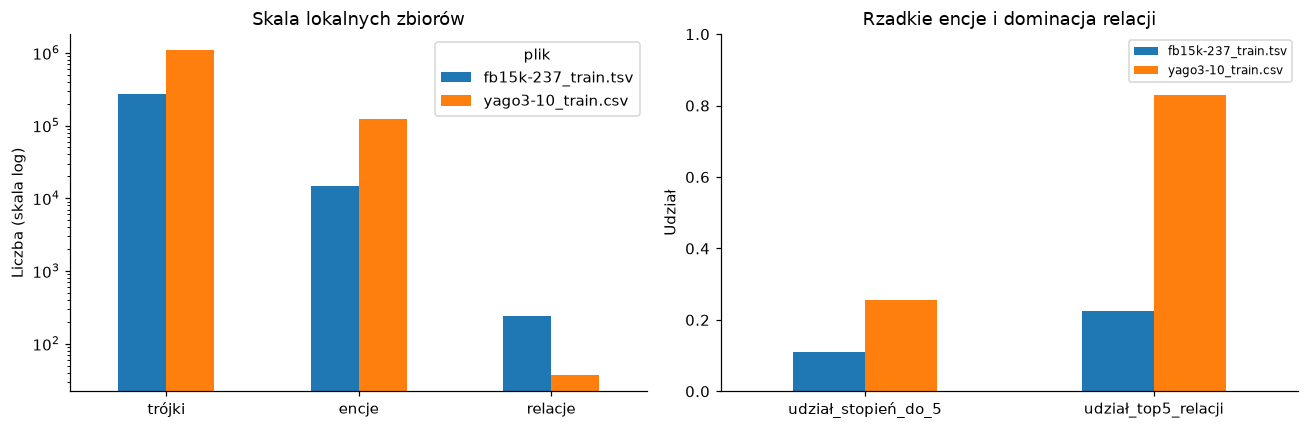

In [13]:
def comparison_row(file_name):
    other_path = DATA_DIR / file_name
    if not other_path.is_file():
        return None
    other = read_triples(other_path)
    ok = ~(other.isna() | other.apply(lambda col: col.str.strip().eq('').fillna(False))).any(axis=1)
    other = other.loc[ok].drop_duplicates()
    other_entities = pd.Index(pd.unique(pd.concat([other['head'], other['tail']], ignore_index=True)))
    other_degree = (other.groupby('head').size().reindex(other_entities, fill_value=0)
                    + other.groupby('tail').size().reindex(other_entities, fill_value=0))
    shares = other['relation'].value_counts(normalize=True)
    return {'plik': file_name, 'trójki': len(other), 'encje': len(other_entities),
            'relacje': other['relation'].nunique(), 'mediana_stopnia': other_degree.median(),
            'udział_stopień_do_5': other_degree.le(5).mean(),
            'udział_top5_relacji': shares.head(5).sum(),
            'efektywne_relacje': 2**float(-(shares * np.log2(shares)).sum())}

comparison_rows = [comparison_row(f) for f in ['fb15k-237_train.tsv', 'yago3-10_train.csv']]
comparison = pd.DataFrame([row for row in comparison_rows if row is not None]).set_index('plik')
display(comparison.round(4))
if len(comparison) == 2:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    comparison[['trójki', 'encje', 'relacje']].T.plot.bar(ax=axes[0], logy=True, rot=0)
    axes[0].set(title='Skala lokalnych zbiorów', ylabel='Liczba (skala log)')
    comparison[['udział_stopień_do_5', 'udział_top5_relacji']].T.plot.bar(ax=axes[1], rot=0)
    axes[1].set(title='Rzadkie encje i dominacja relacji', ylabel='Udział', ylim=(0, 1))
    axes[1].legend(fontsize=8)
    plt.tight_layout()
    plt.show()
